# Floresta Aleatória (_Random Forest_)

## Caso 1: Titanic

[[6] <b>Random Forest Classifier</b>](https://www.edureka.co/blog/random-forest-classifier)  
[Referência local](../random_forest/CompleteTutorialOnRandomForestInR.pdf)  
[Kaggle:Titanic](https://www.kaggle.com/competitions/titanic/overview)

### Preparação do ambiente

In [1]:
rm(list=ls())
options(digits=3)

### Bibliotecas

In [2]:
library(rpart)         # árvores de decisão
library(rpart.plot)    # gráficos de árvores
library(readr)         # leitura de csv
library(repr)          # representações (ajuste gráfico do jupyter)
library(caret)         # matriz de confusão
library(caTools)       # ferramentas em geral; no caso função que divide datasets
library(rattle)        # bibliotecas para o fancyRpartPlot
library(RColorBrewer)  # gradientes de cores

library(randomForest)  # 

Loading required package: ggplot2

Loading required package: lattice

Loading required package: tibble

Loading required package: bitops

Rattle: A free graphical interface for data science with R.
Version 5.5.1 Copyright (c) 2006-2021 Togaware Pty Ltd.
Type 'rattle()' to shake, rattle, and roll your data.

randomForest 4.7-1.2

Type rfNews() to see new features/changes/bug fixes.


Attaching package: ‘randomForest’


The following object is masked from ‘package:rattle’:

    importance


The following object is masked from ‘package:ggplot2’:

    margin




### Funções

In [3]:
grafdim <- function(x=11, y=9) { 
    options(repr.plot.width=x, repr.plot.height=y) 
}

exc <- function(antes, depois) { 
    print(paste("Excluídos:", (antes-depois), ", Restaram:", depois))
}

In [4]:
grafdim()

### Dados

In [5]:
titanic.train <- read.csv("/home/max/ref/d/dataset/titanic_train.csv")

In [6]:
summary(titanic.train)

  PassengerId     Survived         Pclass         Name          
 Min.   :  1   Min.   :0.000   Min.   :1.00   Length:891        
 1st Qu.:224   1st Qu.:0.000   1st Qu.:2.00   Class :character  
 Median :446   Median :0.000   Median :3.00   Mode  :character  
 Mean   :446   Mean   :0.384   Mean   :2.31                     
 3rd Qu.:668   3rd Qu.:1.000   3rd Qu.:3.00                     
 Max.   :891   Max.   :1.000   Max.   :3.00                     
                                                                
     Sex                 Age           SibSp          Parch     
 Length:891         Min.   : 0.4   Min.   :0.00   Min.   :0.00  
 Class :character   1st Qu.:20.1   1st Qu.:0.00   1st Qu.:0.00  
 Mode  :character   Median :28.0   Median :0.00   Median :0.00  
                    Mean   :29.7   Mean   :0.52   Mean   :0.38  
                    3rd Qu.:38.0   3rd Qu.:1.00   3rd Qu.:0.00  
                    Max.   :80.0   Max.   :8.00   Max.   :6.00  
                    NA's 

In [7]:
cat("Há", nrow(titanic.train), 
    "observações no conjunto de dados fornecido como treinamento")

Há 891 observações no conjunto de dados fornecido como treinamento

Variáveis de interesse:
- `Survived` : `0` se não sobreviveu; `1` se sobreviveu;
- `Pclass`: classe do passageiro (`1`ª, `2`ª ou `3`ª classe);
- `Sex`: sexo (`female`, `male`);
- `Age`: idade;
- `SibSp`: número de irmãos, marido/esposa acompanhantes;
- `Parch`: número de pais ou filhos acompanhantes;
- `Fare`: quanto o passageiro pagou na passagem;
- `Embraked`: onde o passageiro embarcou (`C` - Cherbourg, `Q` - Queenstown, `S` - Southpampton).

In [8]:
preparar <- function(df) {
    res             <- data.frame(factor(df$Survived))
    res$Pclass      <- factor(df$Pclass, ordered=TRUE, levels=c(1:3), labels=c("1ª","2ª","3ª"))
    res$Sex         <- factor(df$Sex)
    res$Age         <- df$Age
    res$SibSp       <- factor(df$SibSp, levels=c(0:8))
    res$Parch       <- factor(df$Parch, levels=c(0:9))
    res$Fare        <- df$Fare
    emb             <- df$Embarked
    emb[emb == ""]  <- NA
    res$Embarked    <- factor(emb)
    
    names(res)[1] <- "Survived"
    return(res)
}

In [9]:
titanic <- preparar(titanic.train)
summary(titanic)

 Survived Pclass       Sex           Age           SibSp         Parch    
 0:549    1ª:216   female:314   Min.   : 0.4   0      :608   0      :678  
 1:342    2ª:184   male  :577   1st Qu.:20.1   1      :209   1      :118  
          3ª:491                Median :28.0   2      : 28   2      : 80  
                                Mean   :29.7   4      : 18   3      :  5  
                                3rd Qu.:38.0   3      : 16   5      :  5  
                                Max.   :80.0   8      :  7   4      :  4  
                                NA's   :177    (Other):  5   (Other):  1  
      Fare     Embarked  
 Min.   :  0   C   :168  
 1st Qu.:  8   Q   : 77  
 Median : 14   S   :644  
 Mean   : 32   NA's:  2  
 3rd Qu.: 31             
 Max.   :512             
                         

#### Separação em treino e validação

In [10]:
(num_obs   <- nrow(titanic))
tx_teste   <- 0.2
tx_valid   <- 0.2
(num_teste <- trunc(num_obs * tx_teste))
(num_valid <- trunc(num_obs * tx_valid))
(num_trein <- num_obs - num_teste - num_valid)

[1] 891

[1] 178

[1] 178

[1] 535

In [11]:
set.seed(997)
treino   <- titanic
amostra  <- sample(1:num_obs, num_teste, replace=FALSE)
teste    <- treino[ amostra, ]
treino   <- treino[-amostra, ]

In [12]:
amostra  <- sample(1:(num_obs - num_teste), num_valid, replace=FALSE)
valid    <- treino[ amostra, ]
treino   <- treino[-amostra, ]

In [13]:
cat("Há:\n", 
    nrow(treino), "observações no conjunto de treinamento,\n",
    nrow(teste),  "observações no conjunto de teste,\n",
    nrow(valid),  "observações no conjunto de validação,\n"
   )

Há:
 535 observações no conjunto de treinamento,
 178 observações no conjunto de teste,
 178 observações no conjunto de validação,


In [14]:
# save(treino, valid, teste, file="dados/titanic.RData")

In [15]:
# load("dados/titanic.RData")

Convém avaliar se a proporção de positivos/negativos se mantém nos conjuntos de teste e validação:

In [16]:
proporcao_pos <- function(df, positivo) {
    return (round(sum(df$Survived==positivo)/nrow(df),4))
}

In [17]:
cat("Proporção de sobreviventes nos conjuntos:\n",
    "treino:\t", proporcao_pos(treino, 1), 
    "\n validação:\t", proporcao_pos(valid, 1),
    "\n teste:\t\t", proporcao_pos(teste, 1))

Proporção de sobreviventes nos conjuntos:
 treino:	 0.359 
 validação:	 0.444 
 teste:		 0.399

A proporção de sobreviventes é próxima nos três conjuntos.

### Escolha das variáveis

#### Classe

Avaliando o comportamento de sobreviventes com classe (`Survived` × `Pclass`)

In [18]:
(tab <- table(treino[,c('Survived', 'Pclass')]))

        Pclass
Survived  1ª  2ª  3ª
       0  46  64 233
       1  74  55  63

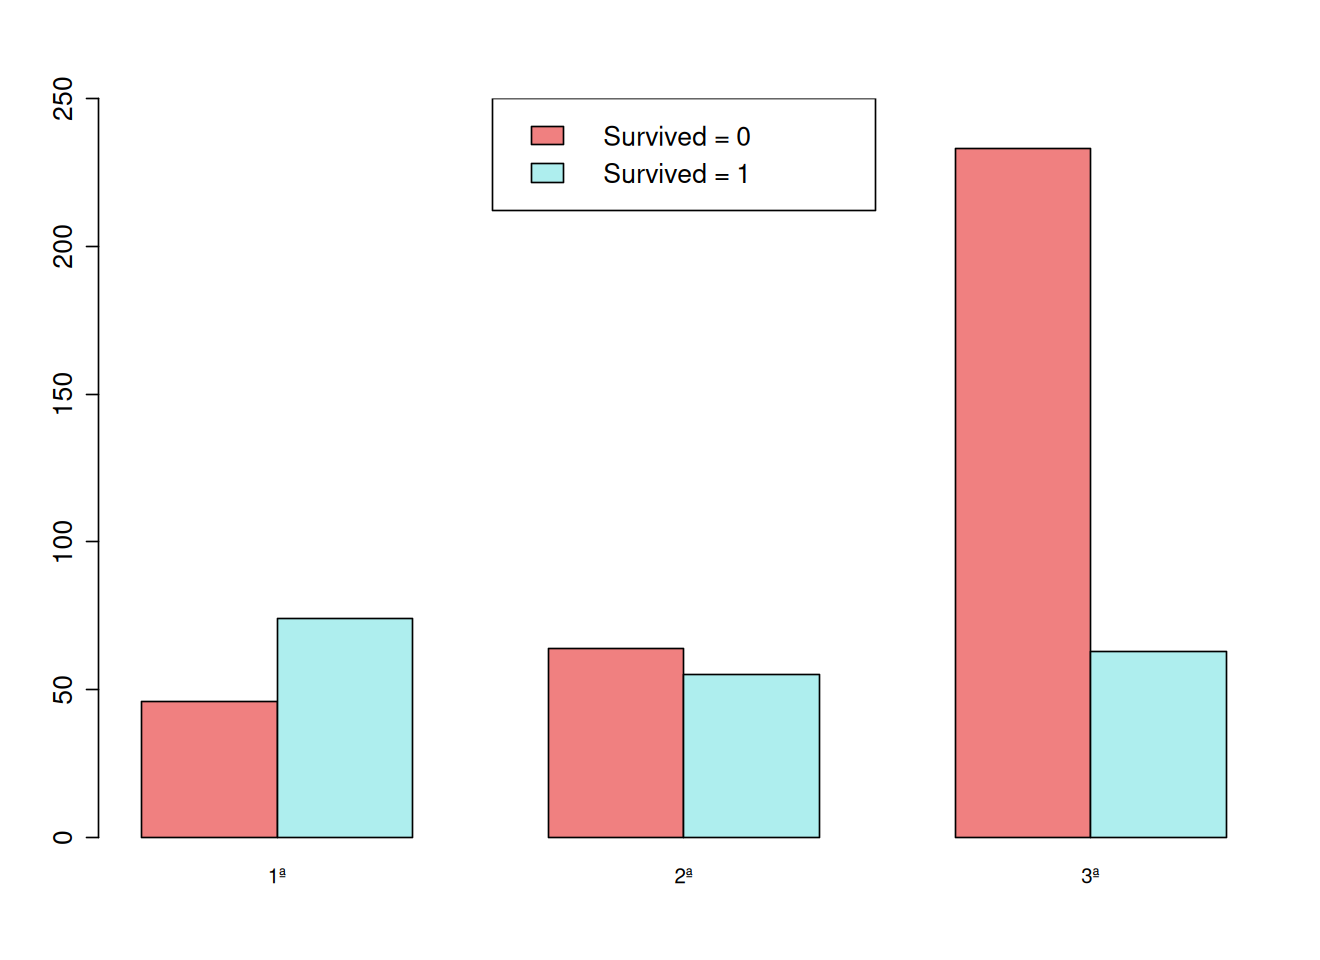

In [19]:
grafdim(11,8)
barplot(tab, beside=TRUE, col=c("lightcoral","paleturquoise2"), 
        ylim=c(0,250), cex.axis=1.3)
legend("top", legend=c("Survived = 0", "Survived = 1"), 
       fill=c("lightcoral","paleturquoise2"), cex=1.3)

Proporcionalmente:

In [20]:
(tab_prop <- prop.table(tab, margin=2))

        Pclass
Survived    1ª    2ª    3ª
       0 0.383 0.538 0.787
       1 0.617 0.462 0.213

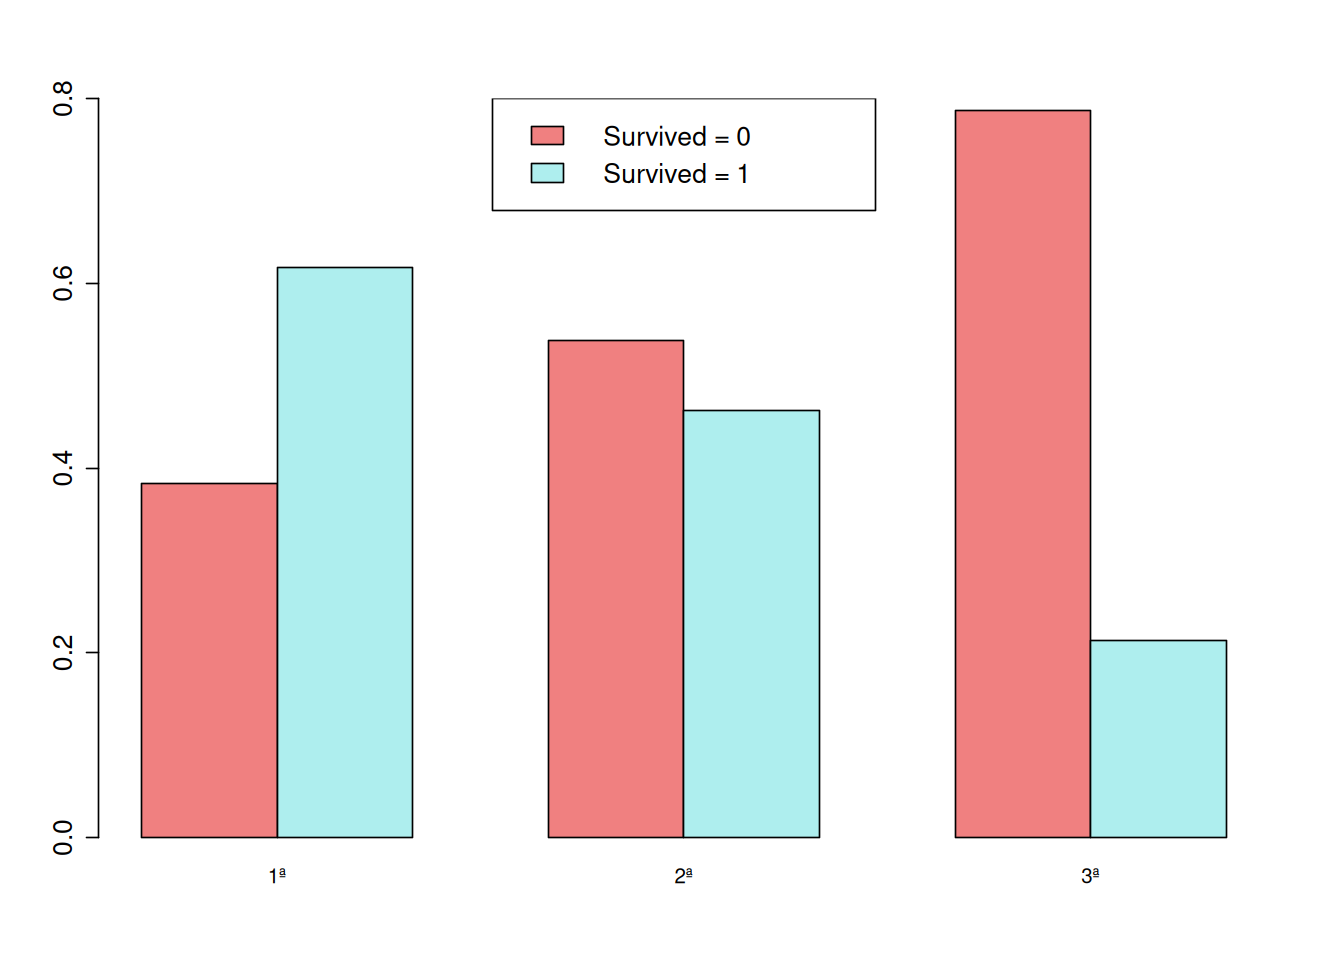

In [21]:
barplot(tab_prop, beside=TRUE, col=c("lightcoral","paleturquoise2"), 
        ylim=c(0,0.8), cex.axis=1.3)
legend("top", legend=c("Survived = 0", "Survived = 1"), 
       fill=c("lightcoral","paleturquoise2"), cex=1.3)

Proporcionalmente, a taxa de sobreviventes cai da 1ª para a 3ª classe.

#### Sexo

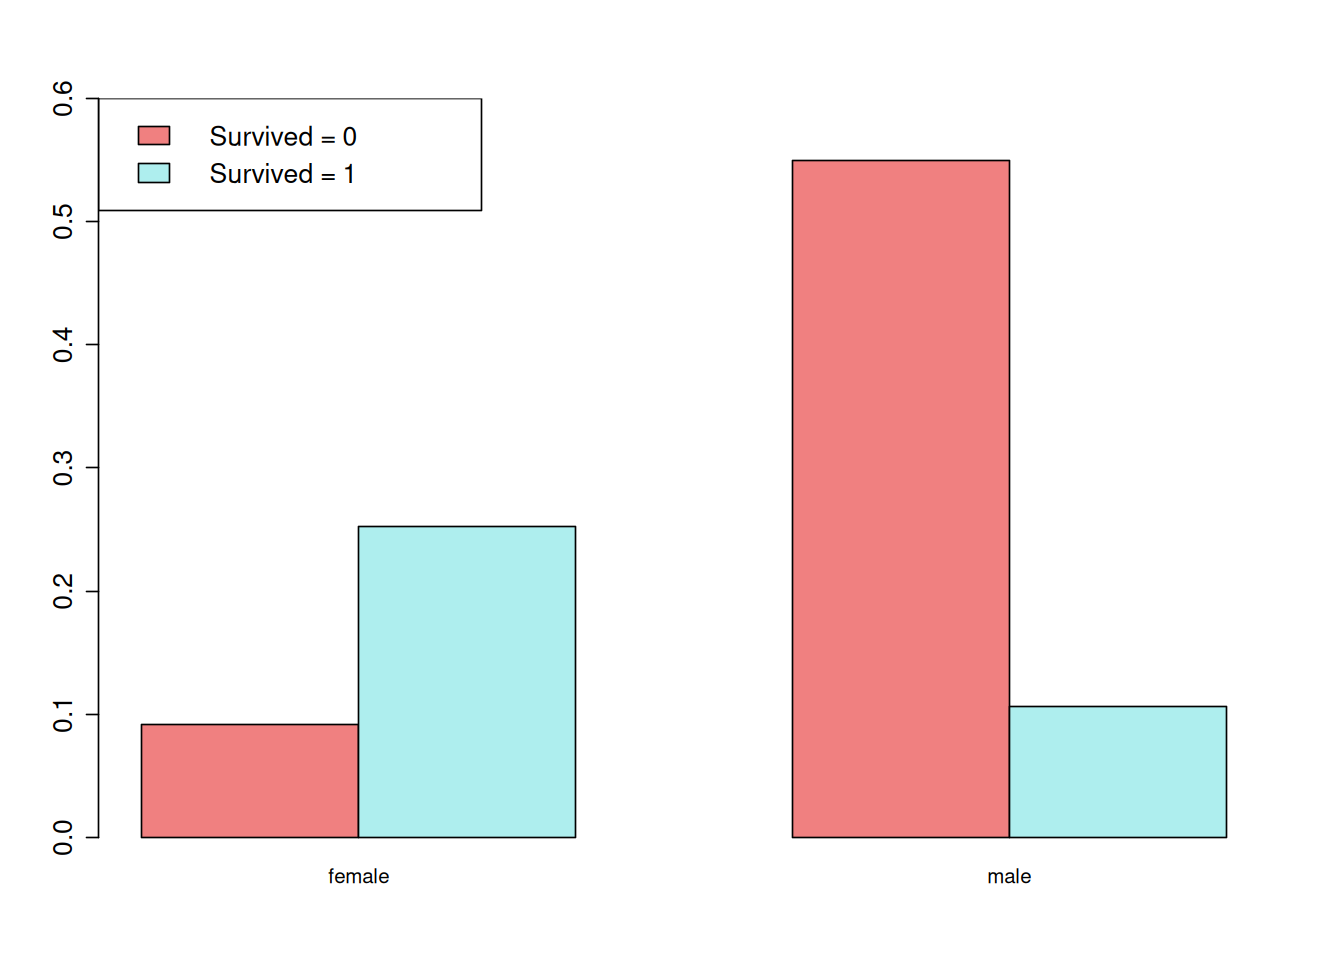

In [22]:
grafdim(11,8)
barplot(prop.table(table(treino[,c('Survived', 'Sex')])), 
        beside=TRUE, col=c("lightcoral","paleturquoise2"), 
        ylim=c(0,0.6), cex.axis=1.3)
legend("topleft", legend=c("Survived = 0", "Survived = 1"), 
       fill=c("lightcoral","paleturquoise2"), cex=1.3)

Há poucos sobreviventes dentre os homens.

#### Idade

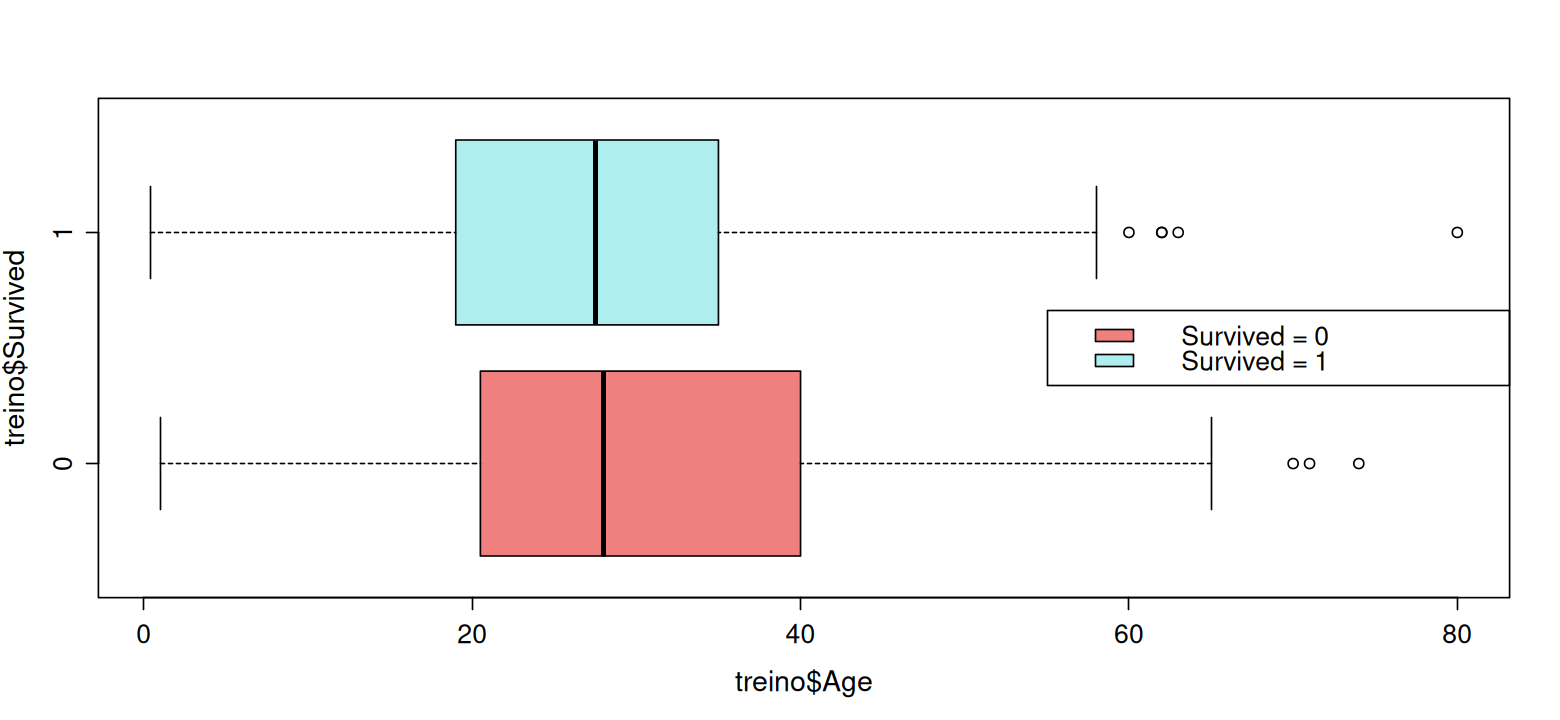

In [23]:
grafdim(13,6)
boxplot(treino$Age ~ treino$Survived, horizontal=TRUE, 
        col=c("lightcoral","paleturquoise2"), cex.axis=1.3, cex.lab=1.4)
legend("right", legend=c("Survived = 0", "Survived = 1"), 
       fill=c("lightcoral","paleturquoise2"), cex=1.3)

Não parece haver distinção de sobreviventes em função da idade.

### Modelo

In [24]:
set.seed(997)

A variável `Age` não será usada pois não apresenta distinção entre sobreviventes ou não e possui muitos dados indisponíveis (`NA`s).

Os `NA`s da variável `Embarked` foram convertidos para a classe mais frequente, no caso, `S`. Deve ser feito tanto para o treino quanto para a validação e o teste..

In [25]:
summary(treino$Embarked)
summary(valid$Embarked)
summary(teste$Embarked)

C    Q    S NA's 
 108   53  372    2

C   Q   S 
 33  14 131

C   Q   S 
 27  10 141

Dependendo da aleatoridade da separação, os 2 `NA`s podem estar em qualquer grupo.
Apenas o treino possui `NA`s para `Embarked`.

In [26]:
treino[is.na(treino$Embarked),"Embarked"] <- "S"
valid[is.na(valid$Embarked),"Embarked"] <- "S"
teste[is.na(teste$Embarked),"Embarked"] <- "S"

In [27]:
summary(treino$Embarked)
summary(valid$Embarked)
summary(teste$Embarked)

C   Q   S 
108  53 374

C   Q   S 
 33  14 131

C   Q   S 
 27  10 141

In [28]:
mod_bas <- train(Survived ~ Pclass + Sex + SibSp + Parch + Fare + Embarked,
                 data=treino,
                 method='rf',                         # algoritmo de "random forest"
                 trControl=trainControl(method="cv"), # usar validação cruzada
                 number=5)                            # usar 5 fatias (folds) para val. cruz.

In [29]:
trn_pred <- predict(mod_bas)
trn_obs  <- treino$Survived

In [30]:
(confmat <- confusionMatrix(table(trn_obs, trn_pred)))

Confusion Matrix and Statistics

       trn_pred
trn_obs   0   1
      0 338   5
      1  26 166
                                       
               Accuracy : 0.942        
                 95% CI : (0.919, 0.96)
    No Information Rate : 0.68         
    P-Value [Acc > NIR] : < 2e-16      
                                       
                  Kappa : 0.871        
                                       
 Mcnemar's Test P-Value : 0.000328     
                                       
            Sensitivity : 0.929        
            Specificity : 0.971        
         Pos Pred Value : 0.985        
         Neg Pred Value : 0.865        
             Prevalence : 0.680        
         Detection Rate : 0.632        
   Detection Prevalence : 0.641        
      Balanced Accuracy : 0.950        
                                       
       'Positive' Class : 0            
                                       

In [31]:
(acc_bal_baseline <- confmat$byClass["Balanced Accuracy"])

Balanced Accuracy 
             0.95

#### Matriz de Confusão - Preditos Treinamento

In [32]:
cmtab <- data.frame(confmat$table)
cmtab$trn_obs <- factor(cmtab$trn_obs, levels=rev(unique(cmtab$trn_obs)))

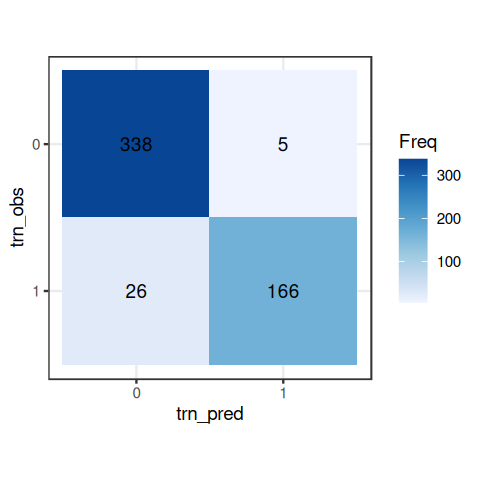

In [33]:
grafdim(4,4)
ggplot(cmtab, aes(x=trn_pred, y=trn_obs, fill=Freq)) +
    geom_tile() + theme_bw() + # tira o fundo cinza
    coord_equal() +
    # palhetas: Reds, Blues, Spectral, RdYlBu, Greens
    scale_fill_distiller(palette="Blues", direction=1) +
#    guides(fill=F) + # tira a legenda Fill
    geom_text(aes(label=Freq), color="black") # rótulos

In [34]:
val_pred <- predict(mod_bas, newdata=valid)
#trn_pred <- mod_bas$pred
val_obs  <- valid$Survived

#### Matriz de Confusão - Preditos Validação

In [35]:
(confmat <- confusionMatrix(table(val_obs, val_pred)))

Confusion Matrix and Statistics

       val_pred
val_obs  0  1
      0 83 16
      1 25 54
                                        
               Accuracy : 0.77          
                 95% CI : (0.701, 0.829)
    No Information Rate : 0.607         
    P-Value [Acc > NIR] : 3.03e-06      
                                        
                  Kappa : 0.528         
                                        
 Mcnemar's Test P-Value : 0.212         
                                        
            Sensitivity : 0.769         
            Specificity : 0.771         
         Pos Pred Value : 0.838         
         Neg Pred Value : 0.684         
             Prevalence : 0.607         
         Detection Rate : 0.466         
   Detection Prevalence : 0.556         
      Balanced Accuracy : 0.770         
                                        
       'Positive' Class : 0             
                                        

In [36]:
(acc_bal_baseline_val <- confmat$byClass["Balanced Accuracy"])

Balanced Accuracy 
             0.77

In [37]:
cmtab <- data.frame(confmat$table)
cmtab$val_obs <- factor(cmtab$val_obs, levels=rev(unique(cmtab$val_obs)))

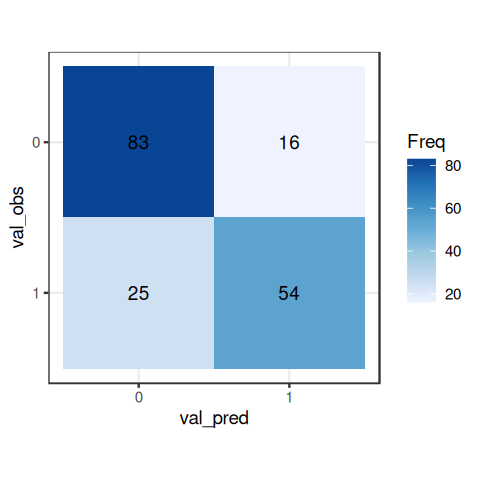

In [38]:
grafdim(4,4)
ggplot(cmtab, aes(x=val_pred, y=val_obs, fill=Freq)) +
    geom_tile() + theme_bw() + # tira o fundo cinza
    coord_equal() +
    # palhetas: Reds, Blues, Spectral, RdYlBu, Greens
    scale_fill_distiller(palette="Blues", direction=1) +
#    guides(fill=F) + # tira a legenda Fill
    geom_text(aes(label=Freq), color="black") # rótulos

### Modelo com `Age` (idade) ajustada

In [39]:
nrow(treino)
summary(treino$Age)

[1] 535

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max.    NA's 
    0.4    20.0    28.0    29.3    38.0    80.0     115 

Apesar da grande quantidade de dados ausentes (107 dentre 534, 20%) seria possível agregar a informação da idade em um modelo, utilizando recursos de contorno como, por exemplo, atribuindo ao valor desconhecido a média de seu grupo, em um esforço de mínima interferência no comportamento da variável.

In [40]:
table(treino$Sex,treino$Pclass)

        
          1ª  2ª  3ª
  female  54  45  85
  male    66  74 211

In [41]:
(sexo   <- unique(treino$Sex))
(classe <- sort(unique(treino$Pclass)))

[1] male   female
Levels: female male

[1] 1ª 2ª 3ª
Levels: 1ª < 2ª < 3ª

In [42]:
(s <- sexo[1])
(p <- classe[1])

[1] male
Levels: female male

[1] 1ª
Levels: 1ª < 2ª < 3ª

In [43]:
idade <- c()
categ <- c()
for (s in sexo) {
    for (p in classe) {
        dados <- treino$Age[treino$Sex==s & treino$Pclass==p] 
        categ <- c(categ, rep(paste(s,"_",p, sep=""), length(dados)))
        idade <- c(idade, dados)
    }
}

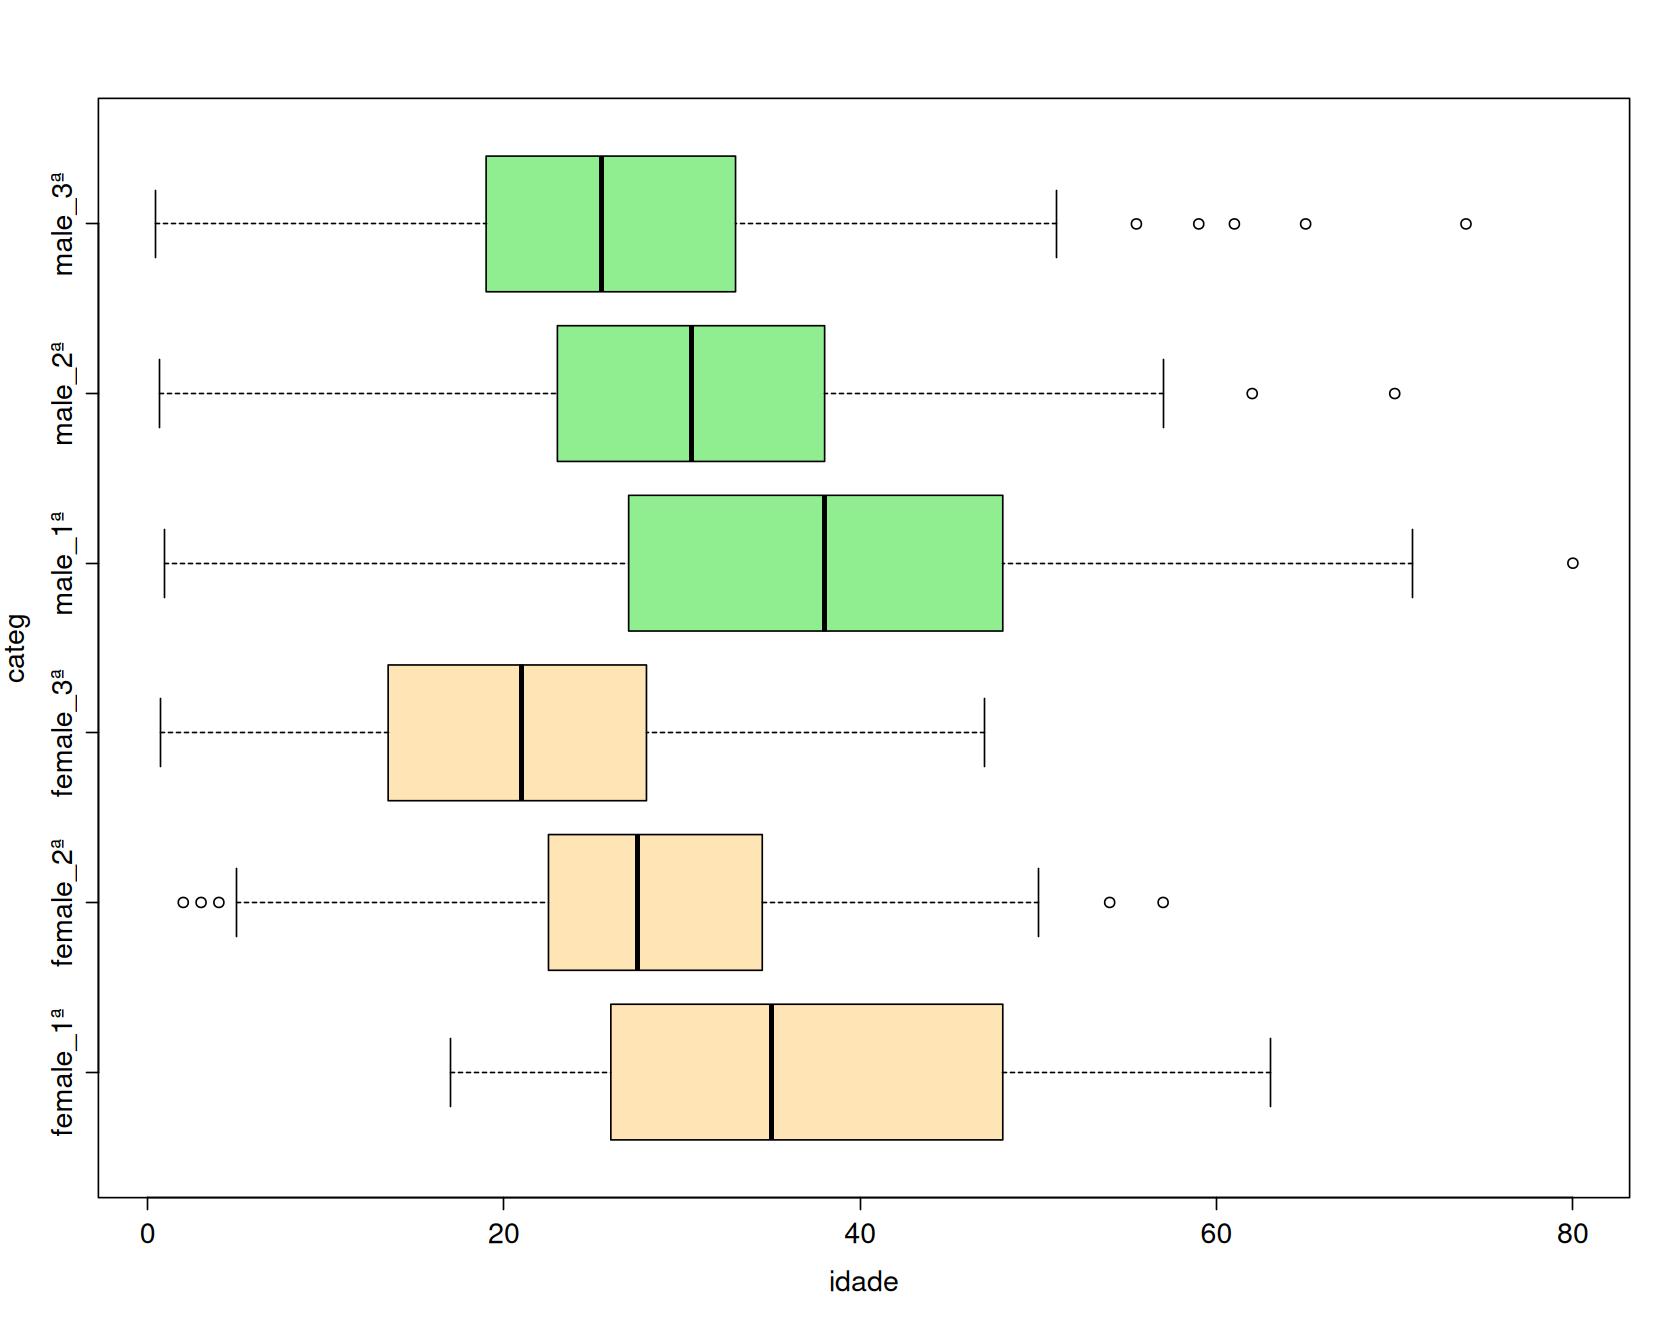

In [44]:
grafdim(14,11)
boxplot(idade ~ categ, horizontal=TRUE, 
        col=c(rep("moccasin",3),rep("lightgreen",3)), cex.lab=1.4, cex.axis=1.4)
rm(dados,categ,idade)

In [45]:
treino$Age_original <- treino$Age
valid$Age_original  <- valid$Age

In [46]:
treino$Age[is.na(treino$Age)] <- mean(treino$Age, na.rm=TRUE)
valid$Age[is.na(valid$Age)] <- mean(valid$Age, na.rm=TRUE)

In [47]:
summary(treino)

 Survived Pclass       Sex           Age           SibSp         Parch    
 0:343    1ª:120   female:184   Min.   : 0.4   0      :359   0      :412  
 1:192    2ª:119   male  :351   1st Qu.:22.0   1      :131   1      : 66  
          3ª:296                Median :29.3   2      : 16   2      : 50  
                                Mean   :29.3   4      : 13   3      :  3  
                                3rd Qu.:34.0   3      :  9   4      :  2  
                                Max.   :80.0   8      :  4   5      :  2  
                                               (Other):  3   (Other):  0  
      Fare     Embarked  Age_original 
 Min.   :  0   C:108    Min.   : 0.4  
 1st Qu.:  8   Q: 53    1st Qu.:20.0  
 Median : 14   S:374    Median :28.0  
 Mean   : 30            Mean   :29.3  
 3rd Qu.: 30            3rd Qu.:38.0  
 Max.   :512            Max.   :80.0  
                        NA's   :115   

In [48]:
summary(valid)

 Survived Pclass      Sex           Age           SibSp         Parch    
 0:99     1ª:50   female: 70   Min.   : 0.8   0      :127   0      :135  
 1:79     2ª:33   male  :108   1st Qu.:22.0   1      : 40   1      : 25  
          3ª:95                Median :30.7   2      :  5   2      : 16  
                               Mean   :30.7   3      :  2   5      :  1  
                               3rd Qu.:36.0   4      :  2   6      :  1  
                               Max.   :71.0   5      :  1   3      :  0  
                                              (Other):  1   (Other):  0  
      Fare     Embarked  Age_original 
 Min.   :  0   C: 33    Min.   : 0.8  
 1st Qu.:  8   Q: 14    1st Qu.:21.0  
 Median : 16   S:131    Median :30.0  
 Mean   : 37            Mean   :30.7  
 3rd Qu.: 39            3rd Qu.:39.0  
 Max.   :512            Max.   :71.0  
                        NA's   :35    

In [49]:
mod_age <- train(Survived ~ Pclass + Sex + SibSp + Parch + Fare + Embarked + Age,
                 data=treino,
                 method='rf',                         # algoritmo de "random forest"
                 trControl=trainControl(method="cv"), # usar validação cruzada
                 number=5)                            # usar 5 fatias (folds) para val. cruz.

In [50]:
print(mod_age)

Random Forest 

535 samples
  7 predictor
  2 classes: '0', '1' 

No pre-processing
Resampling: Cross-Validated (10 fold) 
Summary of sample sizes: 481, 482, 482, 481, 482, 482, ... 
Resampling results across tuning parameters:

  mtry  Accuracy  Kappa
   2    0.770     0.423
  13    0.826     0.612
  24    0.809     0.578

Accuracy was used to select the optimal model using the largest value.
The final value used for the model was mtry = 13.


In [51]:
trn_pred_age <- predict(mod_age)
trn_obs_age  <- treino$Survived

In [52]:
(confmat <- confusionMatrix(table(trn_obs_age, trn_pred_age)))

Confusion Matrix and Statistics

           trn_pred_age
trn_obs_age   0   1
          0 340   3
          1  14 178
                                       
               Accuracy : 0.968        
                 95% CI : (0.95, 0.981)
    No Information Rate : 0.662        
    P-Value [Acc > NIR] : <2e-16       
                                       
                  Kappa : 0.93         
                                       
 Mcnemar's Test P-Value : 0.0153       
                                       
            Sensitivity : 0.960        
            Specificity : 0.983        
         Pos Pred Value : 0.991        
         Neg Pred Value : 0.927        
             Prevalence : 0.662        
         Detection Rate : 0.636        
   Detection Prevalence : 0.641        
      Balanced Accuracy : 0.972        
                                       
       'Positive' Class : 0            
                                       

In [53]:
(acc_bal_age_trn <- confmat$byClass["Balanced Accuracy"])

Balanced Accuracy 
            0.972

#### Matriz de Confusão para Preditos do Treinamento

In [54]:
cmtab <- data.frame(confmat$table)
cmtab$trn_obs_age <- factor(cmtab$trn_obs_age, levels=rev(unique(cmtab$trn_obs_age)))

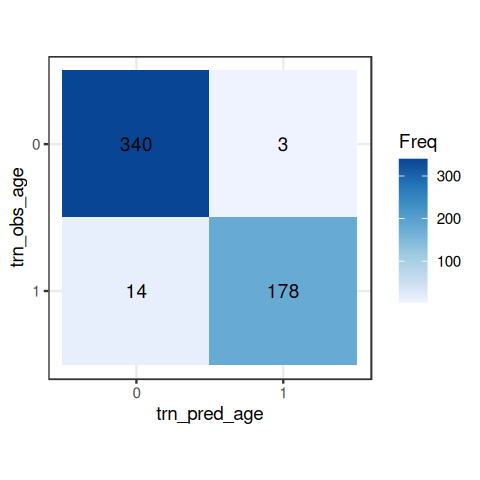

In [55]:
grafdim(4,4)
ggplot(cmtab, aes(x=trn_pred_age, y=trn_obs_age, fill=Freq)) +
    geom_tile() + theme_bw() + # tira o fundo cinza
    coord_equal() +
    # palhetas: Reds, Blues, Spectral, RdYlBu, Greens
    scale_fill_distiller(palette="Blues", direction=1) +
#    guides(fill=F) + # tira a legenda Fill
    geom_text(aes(label=Freq), color="black") # rótulos

#### Matriz de Confusão para Preditos da Validação

In [56]:
val_pred_age <- predict(mod_age, newdata=valid)
#trn_pred <- mod_bas$pred
val_obs_age  <- valid$Survived

In [57]:
(confmat <- confusionMatrix(table(val_obs_age, val_pred_age)))

Confusion Matrix and Statistics

           val_pred_age
val_obs_age  0  1
          0 87 12
          1 29 50
                                        
               Accuracy : 0.77          
                 95% CI : (0.701, 0.829)
    No Information Rate : 0.652         
    P-Value [Acc > NIR] : 0.000446      
                                        
                  Kappa : 0.523         
                                        
 Mcnemar's Test P-Value : 0.012462      
                                        
            Sensitivity : 0.750         
            Specificity : 0.806         
         Pos Pred Value : 0.879         
         Neg Pred Value : 0.633         
             Prevalence : 0.652         
         Detection Rate : 0.489         
   Detection Prevalence : 0.556         
      Balanced Accuracy : 0.778         
                                        
       'Positive' Class : 0             
                                        

In [58]:
(acc_bal_age_val <- confmat$byClass["Balanced Accuracy"])

Balanced Accuracy 
            0.778

In [59]:
cmtab <- data.frame(confmat$table)
cmtab$val_obs_age <- factor(cmtab$val_obs_age, levels=rev(unique(cmtab$val_obs_age)))

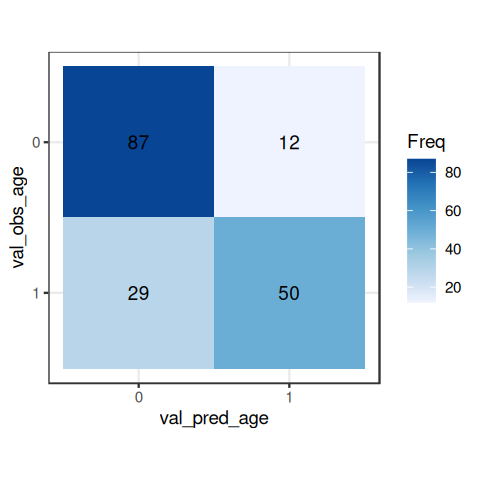

In [60]:
grafdim(4,4)
ggplot(cmtab, aes(x=val_pred_age, y=val_obs_age, fill=Freq)) +
    geom_tile() + theme_bw() + # tira o fundo cinza
    coord_equal() +
    # palhetas: Reds, Blues, Spectral, RdYlBu, Greens
    scale_fill_distiller(palette="Blues", direction=1) +
#    guides(fill=F) + # tira a legenda Fill
    geom_text(aes(label=Freq), color="black") # rótulos

#### Gráfico das Acurácias Balanceadas

In [61]:
nom <- c("baseline", "modelo age")
(abt <- c(acc_bal_baseline, acc_bal_age_trn))
(abv <- c(acc_bal_baseline_val,acc_bal_age_val))

Balanced Accuracy Balanced Accuracy 
            0.950             0.972

Balanced Accuracy Balanced Accuracy 
            0.770             0.778

In [62]:
acc_bal_baseline

Balanced Accuracy 
             0.95

In [63]:
grafdim(8,7)

In [64]:
modelo   <- factor(c(1,1), labels=c("age"))
conjunto <- factor(c(1,2), labels=c("treino","validação"))
acuracia <- c(acc_bal_age_trn, acc_bal_age_val)
dfab <- data.frame(modelo, acuracia, conjunto)
rm(conjunto,acuracia,modelo)
dfab

modelo,acuracia,conjunto
<fct>,<dbl>,<fct>
age,0.972,treino
age,0.778,validação


# Referências

1. [<b>Random Forest with R</b> - www.listendata.com/2014/11/random-forest-with-r](https://www.listendata.com/2014/11/random-forest-with-r.html)
2. [<b>R Random Forest Tutorial</b> - https://www.guru99.com/r-random-forest-tutorial.html](https://www.guru99.com/r-random-forest-tutorial.html)
3. [<b>Complete Tutorial on Random Forest in R</b> - https://www.edureka.co/blog/random-forest-classifier](https://www.edureka.co/blog/random-forest-classifier)